# DM-2 : Boosting et cartes de saillance

Description rapide

In [83]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
from pyparsing import results
seed =42

## 0. Import du dataset MNIST

### A faire
- Des matrices de confusion manquent. Le sujet en demande une « pour chaque combinaison de paramètres ». Vous n’en tracez pas pour les cas binaires, et pour le multiclasse vous n’en avez qu’une par type de classifieur faible.
- Le nombre d’étapes de boosting n’est pas vraiment étudié. Le meilleur n_estimators vaut toujours 100, la borne haute de votre grille : l’accuracy augmente donc encore à 100. Le sujet demande de faire varier ce paramètre. Une courbe accuracy en fonction de n_estimators pour chaque classifieur faible serait plus parlante que le seul meilleur score. Ces valeurs sont déjà calculées dans grid.cv_results_["mean_test_score"].
- Le cas 0–4 contre 5–9, cité dans le sujet, n’est pas encore traité.

### A corriger
- La première matrice de confusion a pour texte alternatif « décision stump », alors que le modèle utilise des arbres de profondeur 20.
- Dans la grid search, le titre de chaque matrice affiche l’accuracy de validation croisée, alors que la matrice est calculée sur le jeu de test.

In [84]:
from sklearn.datasets import fetch_openml

X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
y = y.astype(int)

(70000, 784) (70000,)


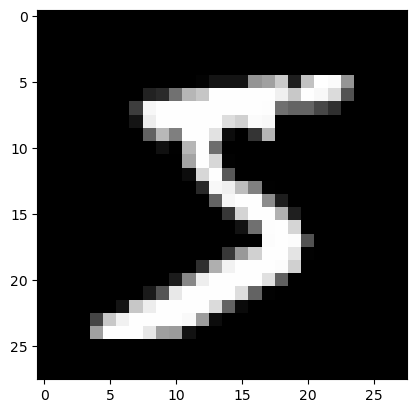

In [67]:
print(X.shape, y.shape)
plt.imshow(X[0, :].reshape(28, 28), cmap="Greys_r")

In [68]:
np.unique_counts(y)

UniqueCountsResult(values=array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), counts=array([6903, 7877, 6990, 7141, 6824, 6313, 6876, 7293, 6825, 6958]))

- Le jeu de données comprend 70000 images aplaties de taille (1, 784) ((28,28) à l'origine).
- Ce sont des chiffres manuscrits entre 0 et 9, les classes peuvent être considérées étant équilibrées.

## 1. Utilisation d’un algorithme de boosting sur de la reconnaissance de chiﬀres manuscrits

Séparation du dataset en set d'entrainnement et de test. \
75 % en entrainnement et 25% en test, car nous avons un grand nombre d'images.

In [85]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=seed)

### A. Première modélisation

Première modelisation avec Adaboost :
- Abre de décision (profondeur maximal de 20)
- nombre d'estimateur : 20
- learning rate : 0.5

In [76]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

Tree_adaboost = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=20),
                                  n_estimators=20,
                                  learning_rate=0.5,
                                  random_state=seed)

Tree_adaboost.fit(X_train, y_train)

Tree_adaboost_score = Tree_adaboost.score(X_test, y_test)
print(f"AdaBoost score: {Tree_adaboost_score}")


KeyboardInterrupt



In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm_Tree_adaboost = confusion_matrix(y_test, Tree_adaboost.predict(X_test))
cm_Tree_adaboost_disp = ConfusionMatrixDisplay(cm_Tree_adaboost)
cm_Tree_adaboost_disp.plot()
cm_Tree_adaboost_disp.ax_.set_title("20 arbres de profondeur 20. Accuracy = 0,9636.")
plt.savefig("images/cm_AdaBoost/cm_Tree_adaboost.png", dpi=300, bbox_inches="tight")

<img src="images/cm_Tree_adaboost.png" alt= "Matrice de confusion décision stump" width="500">

Avec ce premier modèle, on obtient un un score de 0,9636 en test. La matrice de confusion montre de bon resultats avec une majorité de bon classement, surtout pour les 1. Les chiffres les moins bien classées sont les 4, 5 et 8. \
\
Les principales confusions sont :
- les 5 confondu avec des 3
- les 3 confondu avec des 2
- les 9 confondu avec des 4

### B. Gridsearch en variant les classifier faibles

Stratification pour la cross-validation.

In [86]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
folds = skf.split(X_train, y_train)

Réglage des paramètres à teste en GridSearch. On test un nombre d'estimateur faible entre 5 et 100.

In [87]:
from sklearn.linear_model import Perceptron

estimators = {"stump": DecisionTreeClassifier(max_depth=1),
              "tree_d2": DecisionTreeClassifier(max_depth=2),
              "tree_d3": DecisionTreeClassifier(max_depth=3),
              "tree_d5": DecisionTreeClassifier(max_depth=5),
              "tree_d20": DecisionTreeClassifier(max_depth=20),
              "perceptron": Perceptron(max_iter=1000, tol=1e-3, random_state=seed)}

params = {"n_estimators" : [1, 2, 5, 10, 20, 50]}

Réalisation de la cross validation GridSearch. Attention les calculs sont assez long.

[{'estimator': 'stump', 'accuracy': np.float64(0.6373142857142857), 'n_estimators': 50}]
[{'estimator': 'stump', 'accuracy': np.float64(0.6373142857142857), 'n_estimators': 50}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.7896), 'n_estimators': 50}]
[{'estimator': 'stump', 'accuracy': np.float64(0.6373142857142857), 'n_estimators': 50}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.7896), 'n_estimators': 50}, {'estimator': 'tree_d3', 'accuracy': np.float64(0.8458666666666665), 'n_estimators': 50}]
[{'estimator': 'stump', 'accuracy': np.float64(0.6373142857142857), 'n_estimators': 50}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.7896), 'n_estimators': 50}, {'estimator': 'tree_d3', 'accuracy': np.float64(0.8458666666666665), 'n_estimators': 50}, {'estimator': 'tree_d5', 'accuracy': np.float64(0.9065333333333333), 'n_estimators': 50}]
[{'estimator': 'stump', 'accuracy': np.float64(0.6373142857142857), 'n_estimators': 50}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.7

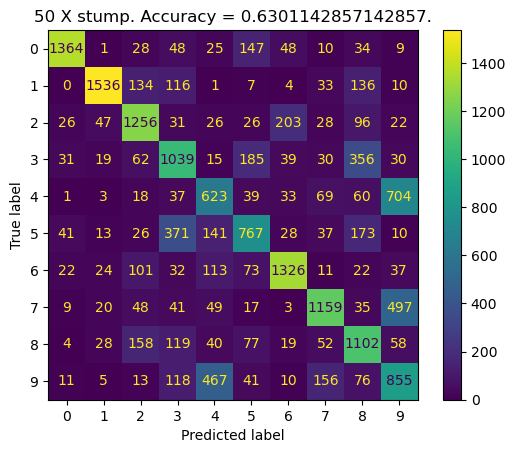

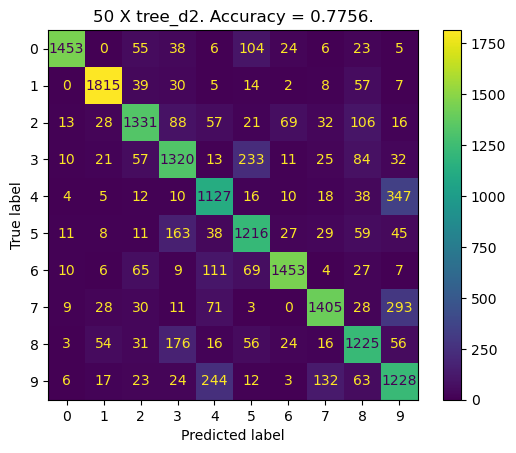

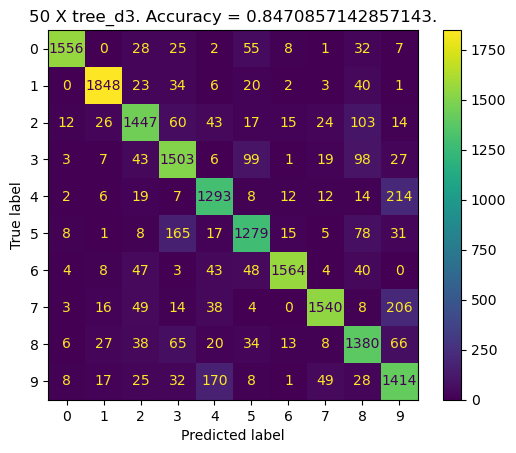

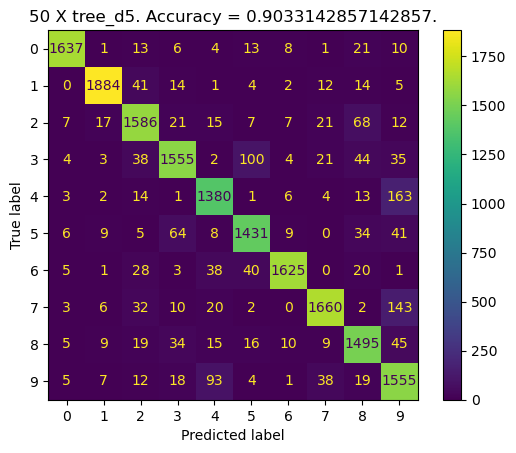

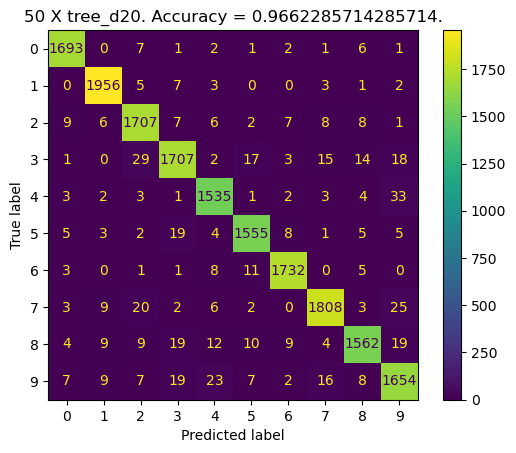

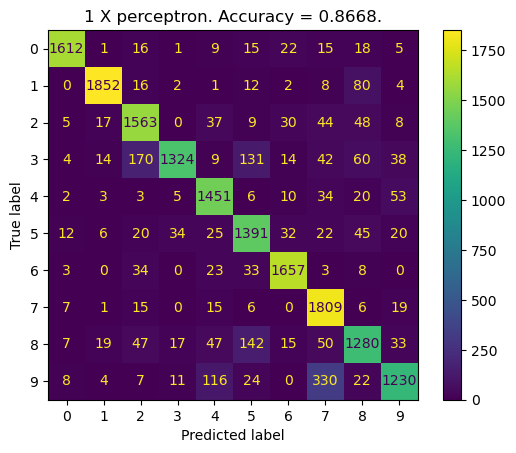

In [88]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

results = []
best_results = []

for estimator_name, estimator in estimators.items():
    ada_boost = AdaBoostClassifier(estimator=estimator, random_state=seed)

    grid = GridSearchCV(estimator=ada_boost, param_grid=params, scoring="accuracy", cv=skf, n_jobs=-1)

    grid.fit(X_train, y_train)
    acc = grid.best_score_
    best = grid.best_estimator_

    # Resultats des cross val
    best_results.append({"estimator" : estimator_name, "accuracy" : acc, "n_estimators" : grid.best_params_["n_estimators"]}) # Meilleurs résultats
    print(best_results)

    df_cv = pd.DataFrame(grid.cv_results_) # Ensemble des résultats
    df_cv["estimator"] = estimator_name
    results.append(df_cv)

    # Matrice de confusion sur le test
    n_estimators = grid.best_params_["n_estimators"]
    y_pred = best.predict(X_test)
    acc_test = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    disp_cm = ConfusionMatrixDisplay(cm)
    disp_cm.plot()
    disp_cm.ax_.set_title(f"{n_estimators} X {estimator_name}. Accuracy = {acc_test}.")
    plt.savefig(f"images/cm_AdaBoost/cm_{estimator_name}.png", dpi=300, bbox_inches="tight")

Construction d'un dataframe avec les resultats de la recherche.

In [89]:
df_cv_all = pd.concat(results, ignore_index=True)
df_accuracy = (df_cv_all.rename(columns={"param_n_estimators": "n_estimators", "mean_test_score": "accuracy_cv", "std_test_score": "std_cv"})[["estimator", "n_estimators", "accuracy_cv", "std_cv"]].sort_values(["estimator", "n_estimators"]).reset_index(drop=True))
#df_accuracy.to_csv("results/AdaBoost_cv_results.csv", sep=";") # transformation en csv
df_accuracy

,estimator,n_estimators,accuracy_cv,std_cv
0,perceptron,1,0.863981,0.011344
1,perceptron,2,0.863981,0.011344
2,perceptron,5,0.825410,0.013703
3,perceptron,10,0.840895,0.009014
4,perceptron,20,0.844419,0.006341
5,perceptron,50,0.847886,0.004686
6,stump,1,0.197067,0.000802
7,stump,2,0.184210,0.000664
8,stump,5,0.217200,0.044985
9,stump,10,0.271390,0.027471


Creation d'un dataframe avec les meilleurs résultats de la recherche.

In [ ]:
df_best_results = pd.DataFrame(best_results, columns=["estimator", "accuracy", "n_estimators"])
df_best_results

<img src="images/cm_AdaBoost/cm_stump.png" alt= "Matrice de confusion décision stump" width="500">

<img src="images/cm_AdaBoost/cm_tree_d2.png" alt= "Matrice de confusion arbre de profondeur 2" width="500">

<img src="images/cm_AdaBoost/cm_tree_d3.png" alt= "Matrice de confusion arbre de profondeur 3" width="500">

<img src="images/cm_AdaBoost/cm_tree_d5.png" alt= "Matrice de confusion arbre de profondeur 5" width="500">

<img src="images/cm_AdaBoost/cm_tree_d20.png" alt= "Matrice de confusion arbre de profondeur 20" width="500">

<img src="images/cm_AdaBoost/cm_perceptron.png" alt= "Matrice de confusion perceptron" width="500">

Evolution de l'accuracy.

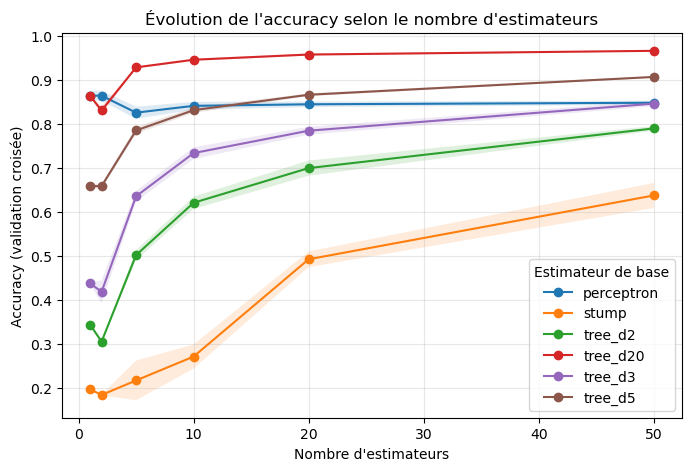

In [93]:
fig, ax = plt.subplots(figsize=(8, 5))

for estimator_name, sub in df_accuracy.groupby("estimator"):
    ax.plot(sub["n_estimators"], sub["accuracy_cv"],
            marker="o", label=estimator_name)
    ax.fill_between(sub["n_estimators"],
                    sub["accuracy_cv"] - sub["std_cv"],
                    sub["accuracy_cv"] + sub["std_cv"],
                    alpha=0.15)

ax.set_xlabel("Nombre d'estimateurs")
ax.set_ylabel("Accuracy (validation croisée)")
ax.set_title("Évolution de l'accuracy selon le nombre d'estimateurs")
ax.legend(title="Estimateur de base")
ax.grid(True, alpha=0.3)
plt.savefig("images/accuracy_vs_n_estimators.png", dpi=300, bbox_inches="tight")
plt.show()

<img src="images/accuracy_vs_n_estimators.png" alt= "Matrice de confusion perceptron" width="500">

### C. Etude de classes binaires

On test ici les classes :
- 9 vs 4
- 5 vs 3

#### 1. 9 vs 4

In [ ]:
mask_9v4 = (y==9) | (y==4)
X_9v4, y_9v4 = X[mask_9v4], (y[mask_9v4] == 9).astype(int)
X_9v4_train, X_9v4_test, y_9v4_train, y_9v4_test = train_test_split(X_9v4, y_9v4, test_size=0.25, random_state=seed)
print(np.unique_counts(y_9v4))


In [ ]:
results_9v4 = []

for estimator_name, estimator in estimators.items():
    ada_boost = AdaBoostClassifier(estimator=estimator, random_state=seed)

    grid = GridSearchCV(estimator=ada_boost, param_grid={"n_estimators" : [20]}, scoring="accuracy", cv=skf, n_jobs=-1)

    grid.fit(X_9v4_train, y_9v4_train)
    acc = grid.best_score_

    results_9v4.append({"estimator" : estimator_name, "accuracy" : acc, "n_estimators" : grid.best_params_["n_estimators"]})
    print(results_9v4)

#### 2. 5 vs 3

In [ ]:
mask_5v3 = (y==5) | (y==3)
X_5v3, y_5v3 = X[mask_5v3], (y[mask_5v3] == 5).astype(int)
X_5v3_train, X_5v3_test, y_5v3_train, y_5v3_test = train_test_split(X_5v3, y_5v3, test_size=0.25, random_state=seed)
print(np.unique_counts(y_5v3))

In [ ]:
results_5v3 = []

for estimator_name, estimator in estimators.items():
    ada_boost = AdaBoostClassifier(estimator=estimator, random_state=seed)

    grid = GridSearchCV(estimator=ada_boost, param_grid={"n_estimators" : [20]}, scoring="accuracy", cv=skf, n_jobs=-1)

    grid.fit(X_5v3_train, y_5v3_train)
    acc = grid.best_score_

    results_5v3.append({"estimator" : estimator_name, "accuracy" : acc, "n_estimators" : grid.best_params_["n_estimators"]})
    print(results_5v3)

#### 3. Groupes de chiffre

## 2. Réalisation de cartes de saillance

## 3. Embedding

Elaboration d'un ensemble de test réduit pour raccourcir les temps de calculs.

In [ ]:
N_TRAIN = 8000           # taille du sous-échantillon train
N_TEST = int(0.25 * N_TRAIN)  # taille du sous-échantillon test

rng = np.random.default_rng(seed)
idx_tr = rng.choice(len(X_train), N_TRAIN, replace=False)
idx_te = rng.choice(len(X_test), N_TEST, replace=False)
X_train_FR, y_train_FR = X_train[idx_tr], y_train[idx_tr]
X_test_FR, y_test_FR = X_test[idx_te], y_test[idx_te]

#### 1. Entrainnement d'un MLP

Apprentissage d'un perceptron multicouche à 1 couche cahé.

In [ ]:
from sklearn.neural_network import MLPRegressor

n_hidden = 64

mlp = MLPRegressor(
    hidden_layer_sizes=(n_hidden,),
    activation="relu",          # fonction d'activagion cachée = relu
    solver="adam",
    max_iter=1000,
    early_stopping=True,        # coupe sur la MSE de reconstruction
    n_iter_no_change=10,
    random_state=seed,
    verbose=True,
        )
mlp.fit(X_train, X_train)


On réalise une fonction d'embedding.

In [ ]:
def embed(mlp, X):
    """Activités de la couche cachée = description dans l'espace de
    redescription. Identique à h = relu(X @ W1 + b1)."""
    Z = X @ mlp.coefs_[0] + mlp.intercepts_[0]
    return np.maximum(Z, 0.0)

On crée une fonction de reconstruction vers l'espace original.

In [ ]:
def reconstruct(mlp, X):
    """Sortie du réseau complet (reconstruction 784 pixels)."""
    return embed(mlp, X) @ mlp.coefs_[1] + mlp.intercepts_[1]

Visualisation des images.

In [ ]:
#autoenc = mlp.predict(X_test_FR)
#recon = reconstruct(autoenc, X_test_FR)

img_idx = 0                     # image de test choisie
img = X_test[img_idx]
#img_rec = reconstruct(autoenc, img[None, :]).reshape(28, 28)
img_rec = mlp.predict(img[None, :]).reshape(28, 28)

fig, axes = plt.subplots(1, 2, figsize=(6, 3.2))
axes[0].imshow(img.reshape(28, 28), cmap="gray")
axes[0].set_title(f"original (test, label {y_test[img_idx]})")
axes[1].imshow(img_rec, cmap="gray")
axes[1].set_title(f"reconstruit ({n_hidden} neurones)")
for ax in axes:
    ax.axis("off")
fig.suptitle(f"Auto-association 784->{n_hidden}->784")
fig.tight_layout()
plt.savefig("images/image1_autoencodage.png", dpi=300, bbox_inches="tight")
plt.close(fig)


#### 2. AdaBoost sur l'embedding

Création des datasets embed

In [ ]:
E_train_FR = embed(mlp, X_train_FR)
E_test_FR = embed(mlp, X_test_FR)
print(f"Embedding train: {E_train_FR.shape}, test: {E_test_FR.shape}")

Paramètres à tester

In [ ]:
from sklearn.linear_model import Perceptron

estimators = {"stump": DecisionTreeClassifier(max_depth=1),
              "tree_d2": DecisionTreeClassifier(max_depth=2),
              "tree_d5": DecisionTreeClassifier(max_depth=5),
              "tree_d20": DecisionTreeClassifier(max_depth=20),
              "perceptron": Perceptron(max_iter=1000, tol=1e-3, random_state=seed)}

params = {"n_estimators" : [20, 50]}

Gridsearch sur l'embedding.

In [ ]:
from sklearn.model_selection import GridSearchCV

results_embed = []
best_results_embed = []

for estimator_name, estimator in estimators.items():
    ada_boost = AdaBoostClassifier(estimator=estimator, random_state=seed)

    grid = GridSearchCV(estimator=ada_boost, param_grid=params, scoring="accuracy", cv=skf, n_jobs=-1)

    grid.fit(E_train_FR, y_train_FR)
    acc = grid.best_score_
    best = grid.best_estimator_

    # Resultats des cross val
    best_results_embed.append({"estimator" : estimator_name, "accuracy" : acc, "n_estimators" : grid.best_params_["n_estimators"]}) # Meilleurs résultats
    print(best_results_embed)

    df_cv = pd.DataFrame(grid.cv_results_) # Ensemble des résultats
    df_cv["estimator"] = estimator_name
    results_embed.append(df_cv)

    # Matrice de confusion sur le test
    n_estimators = grid.best_params_["n_estimators"]
    y_pred = best.predict(E_test_FR)
    acc_test = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test_FR, y_pred)
    disp_cm = ConfusionMatrixDisplay(cm)
    disp_cm.plot()
    disp_cm.ax_.set_title(f"{n_estimators} X {estimator_name}. Accuracy = {acc_test}.")
    plt.savefig(f"images/cm_embedding_{estimator_name}.png", dpi=300, bbox_inches="tight")